# Part B — Final Comparison Notebook


## 1. Setup & Imports

In [1]:
# Code developed/debugged with AI assistance.

import json
import shutil
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from PIL import Image

INPUT_ROOT = Path("/kaggle/input")
OUTPUT_ROOT = Path("/kaggle/working/PartB_Final_Comparison_outputs")
FIGURE_ROOT = OUTPUT_ROOT / "figures"
PACKAGE_ROOT = OUTPUT_ROOT / "final_comparison_package"

for folder in [OUTPUT_ROOT, FIGURE_ROOT, PACKAGE_ROOT]:
    folder.mkdir(parents=True, exist_ok=True)

METHODS = ["SimCLR", "BYOL", "MAE", "DINOv2"]

PARTA_TRAIN_LABELS = 1416
PARTB_FINETUNE_LABELS = 314
TEST_IMAGES = 360

CONFIG = {
    "dataset": "Moroccan Landing Site Segmentation V2",
    "methods": METHODS,
    "part_a_train_labels": PARTA_TRAIN_LABELS,
    "part_b_finetune_labels": PARTB_FINETUNE_LABELS,
    "test_images": TEST_IMAGES,
    "new_split_created": False,
    "retraining_performed": False,
}

display(pd.DataFrame([CONFIG]).T.rename(columns={0: "value"}))

,value
dataset,Moroccan Landing Site Segmentation V2
methods,"[SimCLR, BYOL, MAE, DINOv2]"
part_a_train_labels,1416
part_b_finetune_labels,314
test_images,360
new_split_created,False
retraining_performed,False


## 2. Load Saved Model Results

The four method notebooks save comparison-ready artifacts with slightly different names/schemas.  
This notebook detects and normalizes them automatically.

In [2]:
def matches(name):
    return sorted(
        INPUT_ROOT.rglob(name),
        key=lambda p: (
            "final_comparison_input" not in str(p).lower(),
            len(str(p)),
        ),
    )

def find_first(names):
    for name in names:
        found = matches(name)
        if found:
            return found[0]
    return None

ARTIFACTS = {
    "SimCLR": {
        "comparison": find_first([
            "simclr_comparison_result.json",
            "simclr_comparison_result.csv",
        ]),
        "per_image": find_first([
            "simclr_final_test_per_image_metrics.csv",
            "simclr_worst_test_images.csv",
        ]),
        "worst_plot": find_first([
            "simclr_worst_error_overlays.png",
        ]),
        "confusion_plot": find_first([
            "simclr_confusion_matrix_heatmap.png",
        ]),
    },
    "BYOL": {
        "comparison": find_first([
            "byol_comparison_result.json",
            "byol_comparison_result.csv",
        ]),
        "per_image": find_first([
            "byol_final_test_per_image_metrics.csv",
            "byol_task_f_worst_test_images.csv",
        ]),
        "worst_plot": find_first([
            "byol_task_f_worst_error_analysis.png",
        ]),
        "confusion_plot": find_first([
            "byol_task_e_confusion_matrix.png",
        ]),
    },
    "MAE": {
        "comparison": find_first([
            "mae_comparison_record.json",
            "mae_comparison_row.csv",
        ]),
        "per_image": find_first([
            "mae_task_f_all_test_images.csv",
            "mae_task_f_worst_test_images.csv",
        ]),
        "worst_plot": find_first([
            "mae_task_f_worst_cases_grid.png",
        ]),
        "confusion_plot": find_first([
            "mae_task_e_confusion_matrix.png",
        ]),
    },
    "DINOv2": {
        "comparison": find_first([
            "dinov2_comparison_result.json",
            "dinov2_comparison_result.csv",
            "dinov2_results_for_final_comparison.csv",
        ]),
        "per_image": find_first([
            "dinov2_final_test_per_image_metrics.csv",
            "dinov2_worst_test_images.csv",
        ]),
        "worst_plot": find_first([
            "dinov2_worst_error_overlays.png",
        ]),
        "confusion_plot": find_first([
            "dinov2_confusion_matrix_heatmap.png",
        ]),
    },
}

PARTA_METRICS = find_first(["deeplabv3_metrics.json"])
PARTA_PER_IMAGE = find_first(["deeplabv3_per_image_test_metrics.csv"])
PARTA_WORST_PLOT = find_first([
    "deeplabv3_worst_examples.png",
    "deeplabv3_worst_error_overlays.png",
])

artifact_df = pd.DataFrame([
    {
        "method": method,
        "comparison": str(info["comparison"]) if info["comparison"] else None,
        "per_image": str(info["per_image"]) if info["per_image"] else None,
        "worst_plot": str(info["worst_plot"]) if info["worst_plot"] else None,
        "confusion_plot": (
            str(info["confusion_plot"])
            if info.get("confusion_plot")
            else None
        ),
    }
    for method, info in ARTIFACTS.items()
])

display(artifact_df)

missing = [m for m in METHODS if ARTIFACTS[m]["comparison"] is None]
assert not missing, (
    "Missing comparison artifact for: "
    + ", ".join(missing)
    + ". Attach those notebook outputs via Kaggle Add Input."
)

print("Part-A deeplabv3_metrics.json:", PARTA_METRICS)

,method,comparison,per_image,worst_plot,confusion_plot
0,SimCLR,/kaggle/input/notebooks/fahmidajannat/simclr-p...,/kaggle/input/notebooks/fahmidajannat/simclr-p...,/kaggle/input/notebooks/fahmidajannat/simclr-p...,/kaggle/input/notebooks/fahmidajannat/simclr-p...
1,BYOL,/kaggle/input/notebooks/happysruti/byol-downst...,/kaggle/input/notebooks/happysruti/byol-downst...,/kaggle/input/notebooks/happysruti/byol-downst...,/kaggle/input/notebooks/happysruti/byol-downst...
2,MAE,/kaggle/input/notebooks/teammindnova/mae-downs...,/kaggle/input/notebooks/teammindnova/mae-downs...,/kaggle/input/notebooks/teammindnova/mae-downs...,/kaggle/input/notebooks/teammindnova/mae-downs...
3,DINOv2,/kaggle/input/notebooks/sumu456/dinov2-nb3/Par...,/kaggle/input/notebooks/sumu456/dinov2-nb3/Par...,/kaggle/input/notebooks/sumu456/dinov2-nb3/Par...,/kaggle/input/notebooks/sumu456/dinov2-nb3/Par...


Part-A deeplabv3_metrics.json: None


## 3. Normalize Part-A and SSL Metrics

The notebook first loads the saved Part-A `deeplabv3_metrics.json` when that output is attached.

If the Part-A output is not attached, it falls back to the **exact executed Part-A DeepLabV3 result used by this group** so the final comparison notebook can still run. The fallback values are not re-estimated from the Part-B models.

In [3]:
# Cell 03 - Generic result loading + robust Part-A baseline

def load_record(path):
    path = Path(path)

    if path.suffix.lower() == ".json":
        return json.loads(
            path.read_text(
                encoding="utf-8"
            )
        )

    if path.suffix.lower() == ".csv":
        dataframe = pd.read_csv(
            path
        )

        assert len(dataframe) > 0, (
            f"Empty CSV: {path}"
        )

        return (
            dataframe
            .iloc[0]
            .to_dict()
        )

    raise ValueError(
        f"Unsupported file: {path}"
    )


def first_num(
    record,
    keys,
    default=np.nan,
):
    for key in keys:
        if (
            key in record
            and record[key] is not None
        ):
            try:
                value = float(
                    record[key]
                )

                if np.isfinite(value):
                    return value
            except Exception:
                pass

    return default


def merged_metrics(payload):
    if (
        isinstance(payload, dict)
        and isinstance(
            payload.get("metrics"),
            dict,
        )
    ):
        return {
            **payload,
            **payload["metrics"],
        }

    if isinstance(payload, dict):
        return payload

    return {}


def class_pair(value):
    output = {
        "background": np.nan,
        "landing_site": np.nan,
    }

    if isinstance(value, dict):
        for key, metric_value in value.items():
            try:
                metric_value = float(
                    metric_value
                )
            except Exception:
                continue

            clean_key = (
                str(key)
                .lower()
                .replace("-", "_")
                .replace(" ", "_")
            )

            if (
                "background" in clean_key
                or clean_key == "0"
            ):
                output[
                    "background"
                ] = metric_value

            elif (
                "landing" in clean_key
                or clean_key == "1"
            ):
                output[
                    "landing_site"
                ] = metric_value

    elif isinstance(
        value,
        (list, tuple),
    ):
        if len(value) > 0:
            output[
                "background"
            ] = float(
                value[0]
            )

        if len(value) > 1:
            output[
                "landing_site"
            ] = float(
                value[1]
            )

    return output


def recursive_deeplab(obj):
    if isinstance(obj, dict):
        label = " ".join(
            str(
                obj.get(
                    key,
                    "",
                )
            )
            for key in [
                "model",
                "method",
                "notebook",
                "backbone",
            ]
        ).lower()

        has_iou = any(
            key in obj
            for key in [
                "mean_iou",
                "mIoU",
                "miou",
                "test_mean_iou",
                "test_mIoU",
            ]
        )

        if (
            "deeplab" in label
            and has_iou
        ):
            return obj

        for value in obj.values():
            found = recursive_deeplab(
                value
            )

            if found is not None:
                return found

    elif isinstance(obj, list):
        for value in obj:
            found = recursive_deeplab(
                value
            )

            if found is not None:
                return found

    return None


# ---------------------------------------------------------
# Preferred source: actual Part-A saved output.
# ---------------------------------------------------------
parta_payload = None
parta_source = None


if PARTA_METRICS is not None:
    try:
        parta_payload = load_record(
            PARTA_METRICS
        )

        parta_source = str(
            PARTA_METRICS
        )
    except Exception:
        parta_payload = None


# Also search any attached results.json for a DeepLabV3 record.
if parta_payload is None:
    for candidate in sorted(
        INPUT_ROOT.rglob(
            "results.json"
        )
    ):
        try:
            candidate_record = recursive_deeplab(
                load_record(
                    candidate
                )
            )

            if candidate_record is not None:
                parta_payload = candidate_record
                parta_source = str(
                    candidate
                )
                break

        except Exception:
            continue


# ---------------------------------------------------------
# Robust fallback from the group's executed Part-A NB1.
# These are the exact final test values from the best
# DeepLabV3-ResNet50 checkpoint on the shared Part-A test set.
# ---------------------------------------------------------
PARTA_FALLBACK = {
    "model": "DeepLabV3-ResNet50",
    "test_loss": 0.6501840445730421,
    "mean_iou": 0.8219835756399225,
    "overall_pixel_accuracy": 0.9147978040907118,
    "mean_pixel_accuracy": 0.9013388854171767,
    "mean_dice": 0.9010582406229025,
    "per_class_iou": {
        "background": 0.8831124026957672,
        "landing_site": 0.7608547485840779,
    },
    "per_class_accuracy": {
        "background": 0.9373780891513903,
        "landing_site": 0.8652996816829631,
    },
    "per_class_dice": {
        "background": 0.937928507540547,
        "landing_site": 0.864187973705258,
    },
}


PARTA_FALLBACK_WORST = pd.DataFrame([
    {
        "image_id": "testing_00247",
        "mean_iou": 0.034590,
        "landing_site_iou": 0.039337,
        "background_iou": 0.029842,
    },
    {
        "image_id": "testing_00005",
        "mean_iou": 0.209603,
        "landing_site_iou": 0.250207,
        "background_iou": 0.168999,
    },
    {
        "image_id": "testing_00172",
        "mean_iou": 0.264381,
        "landing_site_iou": 0.000000,
        "background_iou": 0.528763,
    },
    {
        "image_id": "testing_00161",
        "mean_iou": 0.266193,
        "landing_site_iou": 0.291198,
        "background_iou": 0.241188,
    },
    {
        "image_id": "testing_00124",
        "mean_iou": 0.301773,
        "landing_site_iou": 0.000000,
        "background_iou": 0.603546,
    },
])


if parta_payload is None:
    parta_payload = PARTA_FALLBACK
    parta_source = (
        "Embedded fallback: group's executed Part-A "
        "DeepLabV3-ResNet50 NB1 result"
    )

    print(
        "Part-A metrics file was not attached."
    )

    print(
        "Using the verified Part-A DeepLabV3 fallback metrics."
    )

else:
    print(
        "Loaded Part-A metrics from attached output."
    )


PARTA_SOURCE_IS_FALLBACK = (
    str(parta_source).startswith(
        "Embedded fallback:"
    )
)


if PARTA_SOURCE_IS_FALLBACK:
    print(
        "\nSUBMISSION NOTE: Part-A metrics are currently coming from "
        "the verified embedded fallback. For the strictest match to the "
        "Assignment Part B final-comparison wording, attach the executed "
        "Part-A best-model output/results.json before the final Kaggle run."
    )


parta = merged_metrics(
    parta_payload
)

parta_iou = class_pair(
    parta.get(
        "per_class_iou",
        {},
    )
)

parta_dice = class_pair(
    parta.get(
        "per_class_dice",
        parta.get(
            "per_class_f1",
            {},
        ),
    )
)


PARTA_MIOU = first_num(
    parta,
    [
        "mean_iou",
        "mIoU",
        "miou",
        "test_mIoU",
        "test_mean_iou",
    ],
)

PARTA_PIXEL_ACC = first_num(
    parta,
    [
        "overall_pixel_accuracy",
        "pixel_accuracy",
        "pixel_acc",
        "test_pixel_accuracy",
    ],
)

PARTA_DICE = first_num(
    parta,
    [
        "mean_dice_f1",
        "mean_dice",
        "dice",
        "macro_dice",
        "test_mean_dice",
    ],
)


assert np.isfinite(
    PARTA_MIOU
), (
    "Could not resolve Part-A mIoU."
)


print(
    "Part-A metric source:",
    parta_source,
)

print(
    "Part-A mIoU:",
    PARTA_MIOU,
)

print(
    "Part-A Pixel Accuracy:",
    PARTA_PIXEL_ACC,
)

print(
    "Part-A Mean Dice:",
    PARTA_DICE,
)

Part-A metrics file was not attached.
Using the verified Part-A DeepLabV3 fallback metrics.

SUBMISSION NOTE: Part-A metrics are currently coming from the verified embedded fallback. For the strictest match to the Assignment Part B final-comparison wording, attach the executed Part-A best-model output/results.json before the final Kaggle run.
Part-A metric source: Embedded fallback: group's executed Part-A DeepLabV3-ResNet50 NB1 result
Part-A mIoU: 0.8219835756399225
Part-A Pixel Accuracy: 0.9147978040907118
Part-A Mean Dice: 0.9010582406229025


In [4]:
def normalize_method(method, raw):
    r = merged_metrics(raw)
    pi = class_pair(r.get("per_class_iou", {}))
    pdice = class_pair(r.get("per_class_dice", {}))

    if method == "SimCLR":
        miou = first_num(r, ["test_mean_iou", "mean_iou"])
        dice = first_num(r, ["test_mean_dice", "mean_dice"])
        acc = first_num(r, ["test_pixel_accuracy", "pixel_accuracy"])
        labels = first_num(r, ["val_finetune_count"], PARTB_FINETUNE_LABELS)
        parta_labels = first_num(r, ["train_ssl_count"], PARTA_TRAIN_LABELS)
        test_n = first_num(r, ["test_count"], TEST_IMAGES)
        mode = r.get("best_encoder_mode", np.nan)
        epoch50 = first_num(r, ["epoch50_test_miou", "epoch50_monitor_miou"])
        checkpoint_epoch = first_num(r, ["best_finetune_epoch"])
    elif method == "BYOL":
        miou = first_num(r, ["mean_iou", "test_mean_iou"])
        dice = first_num(r, ["mean_dice", "test_mean_dice"])
        acc = first_num(r, ["pixel_accuracy", "test_pixel_accuracy"])
        labels = first_num(r, ["ssl_labelled_finetune_count"], PARTB_FINETUNE_LABELS)
        parta_labels = first_num(r, ["parta_fully_supervised_label_count"], PARTA_TRAIN_LABELS)
        test_n = first_num(r, ["test_count"], TEST_IMAGES)
        mode = r.get("encoder_mode", np.nan)
        epoch50 = first_num(r, ["epoch50_test_miou"])
        checkpoint_epoch = first_num(r, ["best_checkpoint_epoch"])
    elif method == "MAE":
        miou = first_num(r, ["best_test_mean_iou", "test_mean_iou"])
        dice = first_num(r, ["best_test_mean_dice", "test_mean_dice"])
        acc = first_num(r, ["best_test_pixel_accuracy", "test_pixel_accuracy"])
        labels = first_num(r, ["labelled_finetuning_images"], PARTB_FINETUNE_LABELS)
        parta_labels = first_num(r, ["fully_supervised_reference_images"], PARTA_TRAIN_LABELS)
        test_n = first_num(r, ["final_test_images"], TEST_IMAGES)
        mode = r.get("encoder_mode", np.nan)
        epoch50 = first_num(r, ["epoch50_test_mean_iou"])
        checkpoint_epoch = first_num(r, ["best_epoch"])
    elif method == "DINOv2":
        miou = first_num(r, ["test_mean_iou", "mean_iou"])
        dice = first_num(r, ["test_mean_dice", "mean_dice"])
        acc = first_num(r, ["test_pixel_accuracy", "pixel_accuracy"])
        labels = first_num(
            r, ["val_finetune_count", "ssl_labelled_finetune_count"], PARTB_FINETUNE_LABELS
        )
        parta_labels = first_num(
            r, ["train_ssl_count", "partA_train_label_count_baseline"], PARTA_TRAIN_LABELS
        )
        test_n = first_num(r, ["test_count"], TEST_IMAGES)
        mode = r.get("best_encoder_mode", r.get("encoder_mode", np.nan))
        epoch50 = first_num(r, ["epoch50_test_miou", "epoch50_monitor_miou"])
        checkpoint_epoch = first_num(r, ["best_finetune_epoch", "best_checkpoint_epoch"])
    else:
        raise ValueError(method)

    assert np.isfinite(miou), f"mIoU missing for {method}"

    return {
        "Model": method,
        "Encoder Mode": mode,
        "Best Checkpoint Epoch": checkpoint_epoch,
        "Epoch-50 Monitor mIoU": epoch50,
        "mIoU": miou,
        "Background IoU": first_num(r, ["background_iou"], pi["background"]),
        "Landing-site IoU": first_num(r, ["landing_site_iou"], pi["landing_site"]),
        "Pixel Accuracy": acc,
        "Mean Dice": dice,
        "Background Dice": first_num(r, ["background_dice"], pdice["background"]),
        "Landing-site Dice": first_num(r, ["landing_site_dice"], pdice["landing_site"]),
        "Labelled Images": int(labels),
        "Part-A Label Count": int(parta_labels),
        "Test Images": int(test_n),
        "Mean SSL min/epoch": first_num(
            r, ["mean_ssl_epoch_minutes", "ssl_mean_epoch_minutes"]
        ),
        "Mean Downstream min/epoch": first_num(
            r,
            [
                "mean_downstream_epoch_minutes",
                "mean_downstream_epoch_minutes_best_mode",
                "downstream_mean_epoch_minutes",
            ],
        ),
    }

rows = []
raw_records = {}

for method in METHODS:
    raw = load_record(ARTIFACTS[method]["comparison"])
    raw_records[method] = raw
    rows.append(normalize_method(method, raw))

ssl_df = pd.DataFrame(rows)
display(ssl_df)

,Model,Encoder Mode,Best Checkpoint Epoch,Epoch-50 Monitor mIoU,mIoU,Background IoU,Landing-site IoU,Pixel Accuracy,Mean Dice,Background Dice,Landing-site Dice,Labelled Images,Part-A Label Count,Test Images,Mean SSL min/epoch,Mean Downstream min/epoch
0,SimCLR,finetuned,21.0,NaN,0.801791,0.867155,0.736428,0.903116,0.888531,0.928852,0.848210,314,1416,360,NaN,NaN
1,BYOL,finetuned,24.0,0.774605,0.784341,0.856671,0.712012,0.894172,0.877294,0.922803,0.831784,314,1416,360,1.332692,0.161181
2,MAE,finetuned,21.0,0.797678,0.805513,0.871263,0.739763,0.905753,0.890810,0.931203,0.850418,314,1416,360,NaN,NaN
3,DINOv2,finetuned,26.0,0.793307,0.799880,0.863186,0.736574,0.901043,0.887439,0.926570,0.848307,314,1416,360,0.413299,0.111252


## 4. Assignment Consistency Checks

In [5]:
assert set(ssl_df["Labelled Images"]) == {PARTB_FINETUNE_LABELS}, (
    "All four SSL methods must use the same Part-A validation labels."
)
assert set(ssl_df["Part-A Label Count"]) == {PARTA_TRAIN_LABELS}, (
    "Part-A label count mismatch."
)
assert set(ssl_df["Test Images"]) == {TEST_IMAGES}, (
    "All four SSL methods must use the same test split/count."
)

LABEL_RATIO = PARTB_FINETUNE_LABELS / PARTA_TRAIN_LABELS
LABEL_REDUCTION = 1.0 - LABEL_RATIO

print("Part-A train labels:", PARTA_TRAIN_LABELS)
print("Each SSL fine-tuning label count:", PARTB_FINETUNE_LABELS)
print("Label fraction vs Part A:", f"{100 * LABEL_RATIO:.2f}%")
print("Label reduction vs Part A:", f"{100 * LABEL_REDUCTION:.2f}%")
print("Shared test image count:", TEST_IMAGES)
print()
print(
    "Assignment caveat: the Part-A test split is used for both "
    "downstream monitoring/checkpoint selection and final reporting in Part B."
)

Part-A train labels: 1416
Each SSL fine-tuning label count: 314
Label fraction vs Part A: 22.18%
Label reduction vs Part A: 77.82%
Shared test image count: 360

Assignment caveat: the Part-A test split is used for both downstream monitoring/checkpoint selection and final reporting in Part B.


# Task E — Testing, Metrics & Label-Efficiency Comparison

The table below places the Part-A fully-supervised baseline beside all four SSL→fine-tuned models.

In [6]:
parta_row = {
    "Model": "Part-A Best (Fully Supervised)",
    "Encoder Mode": "fully supervised",
    "Best Checkpoint Epoch": np.nan,
    "Epoch-50 Monitor mIoU": np.nan,
    "mIoU": PARTA_MIOU,
    "Background IoU": parta_iou["background"],
    "Landing-site IoU": parta_iou["landing_site"],
    "Pixel Accuracy": PARTA_PIXEL_ACC,
    "Mean Dice": PARTA_DICE,
    "Background Dice": parta_dice["background"],
    "Landing-site Dice": parta_dice["landing_site"],
    "Labelled Images": PARTA_TRAIN_LABELS,
    "Part-A Label Count": PARTA_TRAIN_LABELS,
    "Test Images": TEST_IMAGES,
    "Mean SSL min/epoch": np.nan,
    "Mean Downstream min/epoch": np.nan,
}

comparison_df = pd.concat(
    [pd.DataFrame([parta_row]), ssl_df],
    ignore_index=True,
)

comparison_df["Label Fraction vs Part A"] = (
    comparison_df["Labelled Images"] / PARTA_TRAIN_LABELS
)
comparison_df["mIoU Gap vs Part A"] = comparison_df["mIoU"] - PARTA_MIOU
comparison_df["Part-A mIoU Recovered (%)"] = (
    comparison_df["mIoU"] / PARTA_MIOU * 100.0
)

show_cols = [
    "Model",
    "mIoU",
    "Background IoU",
    "Landing-site IoU",
    "Pixel Accuracy",
    "Mean Dice",
    "Labelled Images",
    "Label Fraction vs Part A",
    "mIoU Gap vs Part A",
    "Part-A mIoU Recovered (%)",
]

display(
    comparison_df[show_cols].style.format({
        "mIoU": "{:.4f}",
        "Background IoU": "{:.4f}",
        "Landing-site IoU": "{:.4f}",
        "Pixel Accuracy": "{:.4f}",
        "Mean Dice": "{:.4f}",
        "Label Fraction vs Part A": "{:.2%}",
        "mIoU Gap vs Part A": "{:+.4f}",
        "Part-A mIoU Recovered (%)": "{:.2f}%",
    })
)

ssl_ranking_df = (
    ssl_df.sort_values("mIoU", ascending=False)
    .reset_index(drop=True)
)

ssl_ranking_df.insert(
    0,
    "Rank",
    np.arange(1, len(ssl_ranking_df) + 1),
)

print("SSL ranking by final test mIoU:")
display(
    ssl_ranking_df[
        ["Rank", "Model", "mIoU", "Landing-site IoU", "Mean Dice"]
    ]
)

comparison_df.to_csv(
    OUTPUT_ROOT / "final_ssl_label_efficiency_comparison.csv",
    index=False,
)
ssl_ranking_df.to_csv(
    OUTPUT_ROOT / "final_ssl_method_ranking.csv",
    index=False,
)

,Model,mIoU,Background IoU,Landing-site IoU,Pixel Accuracy,Mean Dice,Labelled Images,Label Fraction vs Part A,mIoU Gap vs Part A,Part-A mIoU Recovered (%)
0,Part-A Best (Fully Supervised),0.8220,0.8831,0.7609,0.9148,0.9011,1416,100.00%,+0.0000,100.00%
1,SimCLR,0.8018,0.8672,0.7364,0.9031,0.8885,314,22.18%,-0.0202,97.54%
2,BYOL,0.7843,0.8567,0.7120,0.8942,0.8773,314,22.18%,-0.0376,95.42%
3,MAE,0.8055,0.8713,0.7398,0.9058,0.8908,314,22.18%,-0.0165,98.00%
4,DINOv2,0.7999,0.8632,0.7366,0.9010,0.8874,314,22.18%,-0.0221,97.31%


SSL ranking by final test mIoU:


,Rank,Model,mIoU,Landing-site IoU,Mean Dice
0,1,MAE,0.805513,0.739763,0.890810
1,2,SimCLR,0.801791,0.736428,0.888531
2,3,DINOv2,0.799880,0.736574,0.887439
3,4,BYOL,0.784341,0.712012,0.877294


## Task E — Comparison Charts

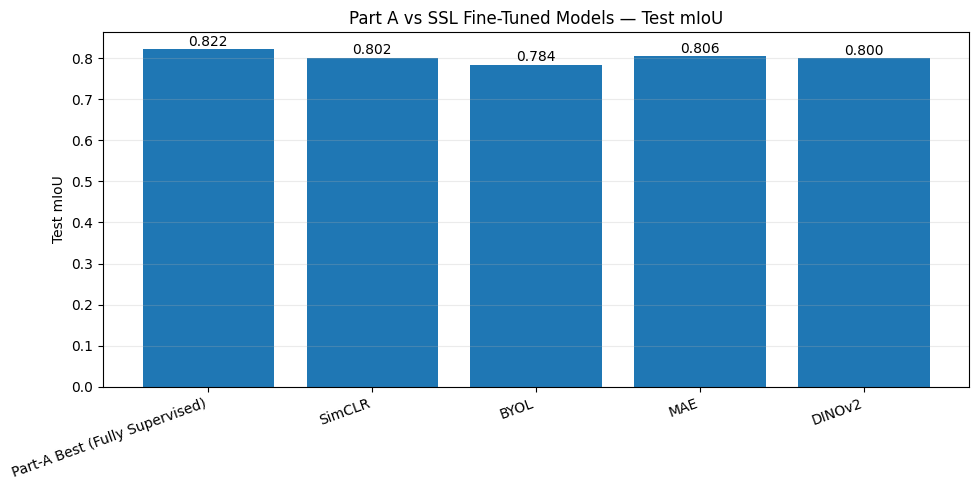

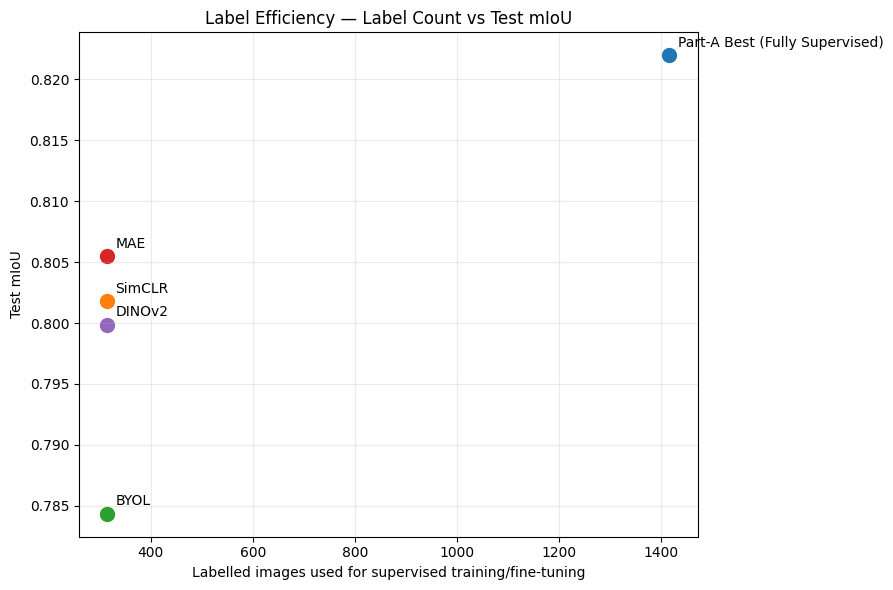

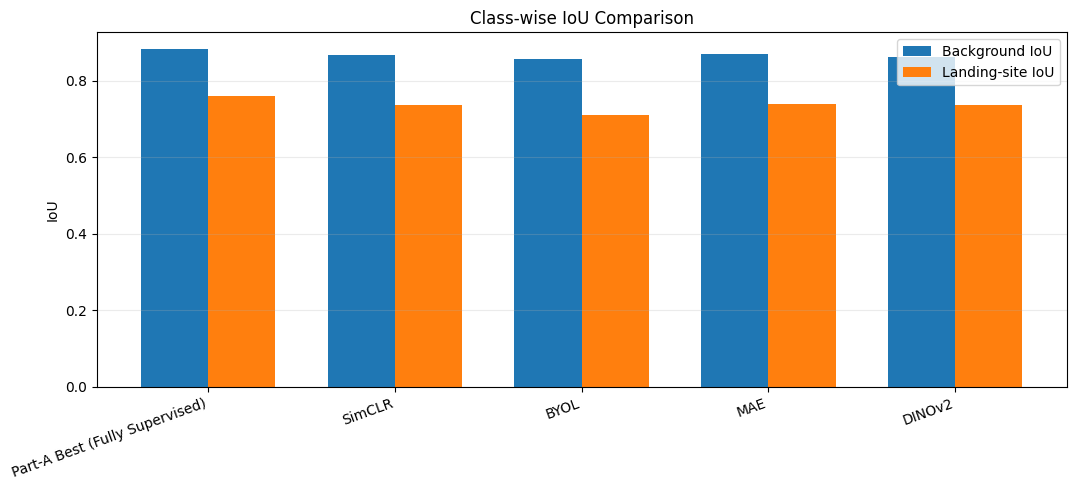

Saved charts:
/kaggle/working/PartB_Final_Comparison_outputs/figures/final_ssl_miou_comparison.png
/kaggle/working/PartB_Final_Comparison_outputs/figures/final_ssl_label_efficiency_chart.png
/kaggle/working/PartB_Final_Comparison_outputs/figures/final_ssl_classwise_iou_comparison.png


In [7]:
# mIoU comparison

plt.figure(figsize=(10, 5))
bars = plt.bar(comparison_df["Model"], comparison_df["mIoU"])
plt.ylabel("Test mIoU")
plt.title("Part A vs SSL Fine-Tuned Models — Test mIoU")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.25)

for bar, value in zip(bars, comparison_df["mIoU"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.008,
        f"{value:.3f}",
        ha="center",
    )

plt.tight_layout()
MIOU_CHART = FIGURE_ROOT / "final_ssl_miou_comparison.png"
plt.savefig(MIOU_CHART, dpi=160)
plt.show()


# Label efficiency

plt.figure(figsize=(9, 6))

for _, row in comparison_df.iterrows():
    plt.scatter(row["Labelled Images"], row["mIoU"], s=100)
    plt.annotate(
        row["Model"],
        (row["Labelled Images"], row["mIoU"]),
        xytext=(6, 6),
        textcoords="offset points",
    )

plt.xlabel("Labelled images used for supervised training/fine-tuning")
plt.ylabel("Test mIoU")
plt.title("Label Efficiency — Label Count vs Test mIoU")
plt.grid(alpha=0.25)
plt.tight_layout()

LABEL_CHART = FIGURE_ROOT / "final_ssl_label_efficiency_chart.png"
plt.savefig(LABEL_CHART, dpi=160)
plt.show()


# Class-wise IoU

x = np.arange(len(comparison_df))
width = 0.36

plt.figure(figsize=(11, 5))
plt.bar(
    x - width / 2,
    comparison_df["Background IoU"],
    width,
    label="Background IoU",
)
plt.bar(
    x + width / 2,
    comparison_df["Landing-site IoU"],
    width,
    label="Landing-site IoU",
)

plt.xticks(
    x,
    comparison_df["Model"],
    rotation=20,
    ha="right",
)
plt.ylabel("IoU")
plt.title("Class-wise IoU Comparison")
plt.legend()
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()

CLASS_CHART = FIGURE_ROOT / "final_ssl_classwise_iou_comparison.png"
plt.savefig(CLASS_CHART, dpi=160)
plt.show()

print("Saved charts:")
print(MIOU_CHART)
print(LABEL_CHART)
print(CLASS_CHART)

## Task E — Final Confusion Matrices (All 4 SSL Models)

This final comparison uses one combined **2×2 figure**: SimCLR, BYOL, MAE, and DINOv2. Each panel is loaded directly from the confusion-matrix PNG saved by the corresponding executed model notebook.

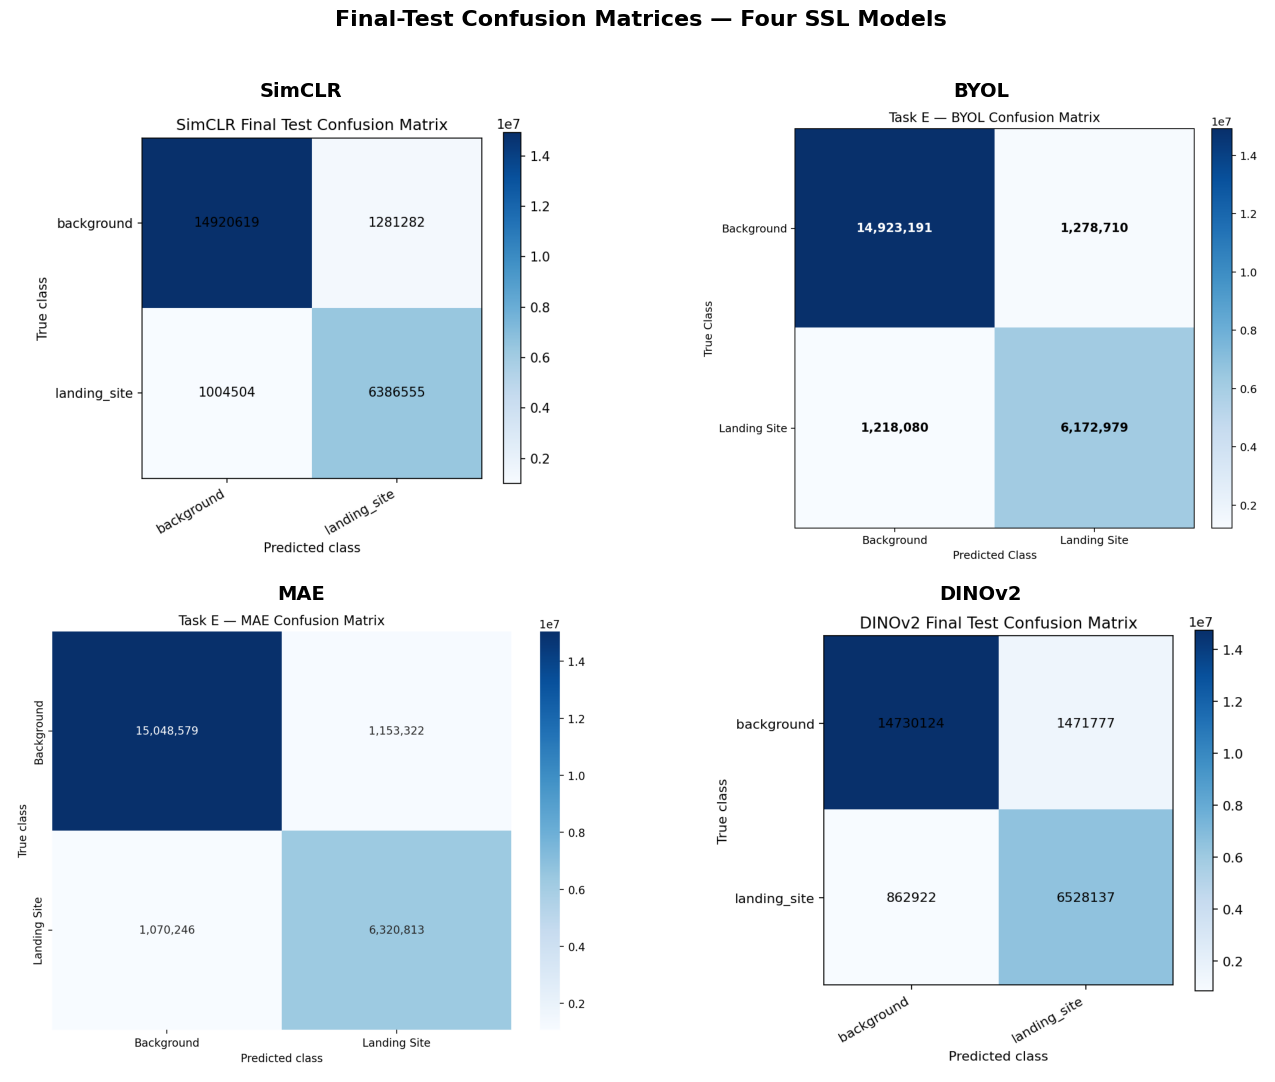

Saved: /kaggle/working/PartB_Final_Comparison_outputs/figures/all_four_ssl_confusion_matrices_2x2.png


In [8]:
# Task E - One combined 2x2 confusion-matrix figure

confusion_paths = {
    method:
        ARTIFACTS[
            method
        ].get(
            "confusion_plot"
        )
    for method
    in METHODS
}


missing_confusion_plots = [
    method
    for method, path
    in confusion_paths.items()
    if (
        path is None
        or not Path(
            path
        ).exists()
    )
]


assert not missing_confusion_plots, (
    "Missing saved confusion-matrix figure for: "
    + ", ".join(
        missing_confusion_plots
    )
    + ". Attach all four executed method outputs through Kaggle Add Input."
)


fig, axes = plt.subplots(
    2,
    2,
    figsize=(14, 11),
)


panel_order = [
    ("SimCLR", axes[0, 0]),
    ("BYOL", axes[0, 1]),
    ("MAE", axes[1, 0]),
    ("DINOv2", axes[1, 1]),
]


for method, axis in panel_order:
    image = Image.open(
        confusion_paths[
            method
        ]
    ).convert(
        "RGB"
    )

    axis.imshow(
        image
    )

    axis.set_title(
        method,
        fontsize=14,
        fontweight="bold",
    )

    axis.axis(
        "off"
    )


fig.suptitle(
    "Final-Test Confusion Matrices — Four SSL Models",
    fontsize=16,
    fontweight="bold",
)


plt.tight_layout(
    rect=[
        0,
        0,
        1,
        0.96,
    ]
)


CONFUSION_GRID_PATH = (
    FIGURE_ROOT
    / "all_four_ssl_confusion_matrices_2x2.png"
)


plt.savefig(
    CONFUSION_GRID_PATH,
    dpi=180,
    bbox_inches="tight",
)

plt.show()


print(
    "Saved:",
    CONFUSION_GRID_PATH
)

## Task E — Label-Efficiency Discussion

The cell below generates the required short Task-E discussion directly from the loaded final results, so the wording stays consistent with the actual values produced by this notebook.

In [9]:
# Task E - Short result-based label-efficiency discussion

best_ssl = (
    ssl_ranking_df
    .iloc[0]
)


best_gap = (
    float(
        best_ssl[
            "mIoU"
        ]
    )
    -
    float(
        PARTA_MIOU
    )
)


best_recovered = (
    float(
        best_ssl[
            "mIoU"
        ]
    )
    /
    float(
        PARTA_MIOU
    )
    *
    100.0
)


task_e_discussion = (
    f"The Part-A fully supervised model achieved an mIoU of "
    f"{PARTA_MIOU:.4f} using {PARTA_TRAIN_LABELS} labelled training images. "
    f"In Part B, each SSL model was fine-tuned using only "
    f"{PARTB_FINETUNE_LABELS} labelled validation images, which is "
    f"{100 * LABEL_RATIO:.2f}% of the Part-A labelled training set and "
    f"represents a {100 * LABEL_REDUCTION:.2f}% reduction in labelled data. "
    f"Among the four SSL methods, {best_ssl['Model']} achieved the highest "
    f"test mIoU of {float(best_ssl['mIoU']):.4f}. Its absolute gap from the "
    f"Part-A baseline was {abs(best_gap):.4f} mIoU, recovering approximately "
    f"{best_recovered:.2f}% of the Part-A mIoU. Therefore, based on the "
    f"final test results, {best_ssl['Model']} produced the strongest "
    f"label-efficiency result among the four SSL methods."
)


print(
    task_e_discussion
)


task_e_discussion_path = (
    OUTPUT_ROOT
    / "task_e_label_efficiency_discussion.txt"
)


task_e_discussion_path.write_text(
    task_e_discussion,
    encoding="utf-8",
)


print(
    "\\nSaved:",
    task_e_discussion_path
)

The Part-A fully supervised model achieved an mIoU of 0.8220 using 1416 labelled training images. In Part B, each SSL model was fine-tuned using only 314 labelled validation images, which is 22.18% of the Part-A labelled training set and represents a 77.82% reduction in labelled data. Among the four SSL methods, MAE achieved the highest test mIoU of 0.8055. Its absolute gap from the Part-A baseline was 0.0165 mIoU, recovering approximately 98.00% of the Part-A mIoU. Therefore, based on the final test results, MAE produced the strongest label-efficiency result among the four SSL methods.
\nSaved: /kaggle/working/PartB_Final_Comparison_outputs/task_e_label_efficiency_discussion.txt


In [10]:
best_ssl = ssl_ranking_df.iloc[0]

task_e_numbers = pd.DataFrame([{
    "Part-A mIoU": PARTA_MIOU,
    "Best SSL Method": best_ssl["Model"],
    "Best SSL mIoU": best_ssl["mIoU"],
    "Best SSL Gap vs Part A": best_ssl["mIoU"] - PARTA_MIOU,
    "Part-A Labelled Images": PARTA_TRAIN_LABELS,
    "SSL Labelled Images": PARTB_FINETUNE_LABELS,
    "SSL Label Fraction": LABEL_RATIO,
    "Label Reduction": LABEL_REDUCTION,
}])

display(task_e_numbers)

task_e_numbers.to_csv(
    OUTPUT_ROOT / "task_e_objective_numbers.csv",
    index=False,
)

,Part-A mIoU,Best SSL Method,Best SSL mIoU,Best SSL Gap vs Part A,Part-A Labelled Images,SSL Labelled Images,SSL Label Fraction,Label Reduction
0,0.821984,MAE,0.805513,-0.016471,1416,314,0.221751,0.778249


# Task F — Consolidated Error Analysis

This section consolidates the already-saved per-image error evidence from the four SSL methods.

It computes worst-image overlap objectively. The explanation of **why** the methods fail must be written by the group.

Loaded error tables: ['SimCLR', 'BYOL', 'MAE', 'DINOv2', 'Part-A']
Part-A error source: Embedded fallback: executed Part-A worst-5 test images


,Model,Worst Rank,image_id,mean_iou
0,SimCLR,1,testing_00247,0.091417
1,SimCLR,2,testing_00088,0.219792
2,SimCLR,3,testing_00139,0.234981
3,SimCLR,4,testing_00124,0.312161
4,SimCLR,5,testing_00221,0.335172
5,BYOL,1,testing_00247,0.069434
6,BYOL,2,testing_00154,0.192703
7,BYOL,3,testing_00088,0.207199
8,BYOL,4,testing_00205,0.277784
9,BYOL,5,testing_00341,0.325321


Worst-5 shared-image counts:


,SimCLR,BYOL,MAE,DINOv2,Part-A
SimCLR,5,2,2,2,2
BYOL,2,5,2,2,1
MAE,2,2,5,1,0
DINOv2,2,2,1,5,1
Part-A,2,1,0,1,5


Worst-5 Jaccard overlap:


,SimCLR,BYOL,MAE,DINOv2,Part-A
SimCLR,1.00,0.25,0.25,0.25,0.25
BYOL,0.25,1.00,0.25,0.25,0.11
MAE,0.25,0.25,1.00,0.11,0.00
DINOv2,0.25,0.25,0.11,1.00,0.11
Part-A,0.25,0.11,0.00,0.11,1.00


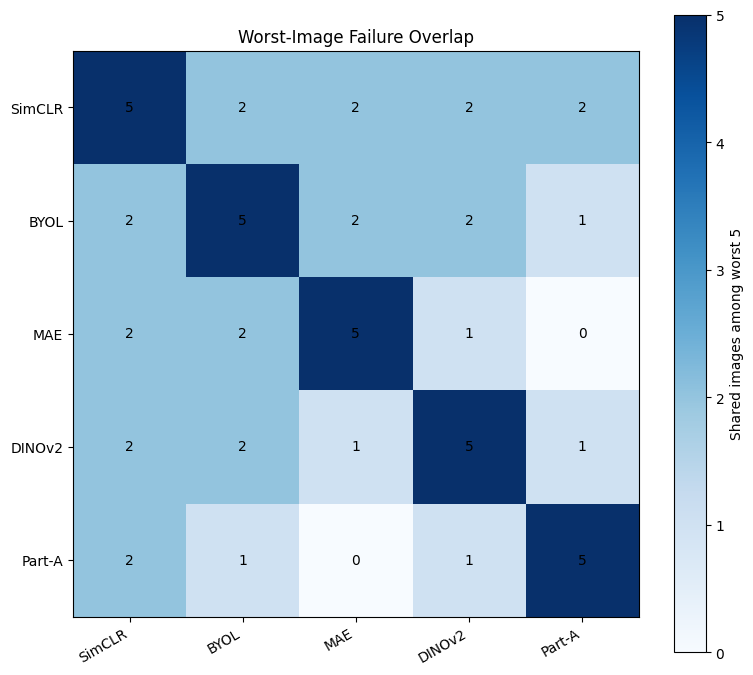

\nObjective class-level failure comparison:


,Model,Background IoU,Landing-site IoU,Lower-IoU Class,Class IoU Gap
0,Part-A Best (Fully Supervised),0.883112,0.760855,Landing Site,0.122258
1,SimCLR,0.867155,0.736428,Landing Site,0.130727
2,BYOL,0.856671,0.712012,Landing Site,0.144659
3,MAE,0.871263,0.739763,Landing Site,0.131500
4,DINOv2,0.863186,0.736574,Landing Site,0.126612


\nWorst-image overlap against Part-A:


,SSL Method,Shared Worst Images with Part-A,Compared Worst-N,Shared Image IDs
0,SimCLR,2,5,"testing_00124, testing_00247"
1,BYOL,1,5,testing_00247
2,MAE,0,5,none
3,DINOv2,1,5,testing_00247


\nImages appearing in the worst set of multiple SSL methods:


,image_id,Number of SSL Methods,Also in Part-A Worst Set
0,testing_00088,4,False
1,testing_00247,3,True
2,testing_00205,2,False
3,testing_00221,2,False


In [11]:
# Cell 11 - Load and normalize per-image error tables

def normalize_per_image(df):
    df = df.copy()

    if "image_id" not in df.columns:
        candidates = [
            column
            for column in df.columns
            if (
                "image" in column.lower()
                and "id" in column.lower()
            )
        ]

        if candidates:
            df = df.rename(
                columns={
                    candidates[0]:
                        "image_id"
                }
            )

    if "mean_iou" not in df.columns:
        candidates = [
            column
            for column in df.columns
            if (
                "iou" in column.lower()
                and "landing" not in column.lower()
                and "background" not in column.lower()
            )
        ]

        if candidates:
            df = df.rename(
                columns={
                    candidates[0]:
                        "mean_iou"
                }
            )

    assert "image_id" in df.columns
    assert "mean_iou" in df.columns

    df["image_id"] = (
        df["image_id"]
        .astype(str)
    )

    df["mean_iou"] = pd.to_numeric(
        df["mean_iou"],
        errors="coerce",
    )

    return df.dropna(
        subset=[
            "mean_iou"
        ]
    )


per_image = {}


for method in METHODS:
    path = ARTIFACTS[
        method
    ][
        "per_image"
    ]

    if path:
        per_image[
            method
        ] = normalize_per_image(
            pd.read_csv(
                path
            )
        )


# Preferred Part-A source: full per-image output if attached.
if PARTA_PER_IMAGE:
    per_image[
        "Part-A"
    ] = normalize_per_image(
        pd.read_csv(
            PARTA_PER_IMAGE
        )
    )

    parta_error_source = str(
        PARTA_PER_IMAGE
    )

else:
    # Fall back to the executed Part-A worst-5 table.
    per_image[
        "Part-A"
    ] = PARTA_FALLBACK_WORST.copy()

    parta_error_source = (
        "Embedded fallback: executed Part-A worst-5 test images"
    )


print(
    "Loaded error tables:",
    list(
        per_image.keys()
    ),
)

print(
    "Part-A error source:",
    parta_error_source,
)


# Five is used so every method is compared against the same number
# of worst cases, including the Part-A fallback table.
WORST_N = 5

worst_sets = {}
worst_rows = []


for method, df in per_image.items():
    worst = (
        df
        .nsmallest(
            min(
                WORST_N,
                len(df),
            ),
            "mean_iou",
        )
        .copy()
    )

    worst_sets[
        method
    ] = set(
        worst[
            "image_id"
        ]
    )

    for rank, (_, row) in enumerate(
        worst.iterrows(),
        start=1,
    ):
        worst_rows.append({
            "Model": method,
            "Worst Rank": rank,
            "image_id": row[
                "image_id"
            ],
            "mean_iou": row[
                "mean_iou"
            ],
        })


consolidated_worst_df = pd.DataFrame(
    worst_rows
)


display(
    consolidated_worst_df
)


names = list(
    worst_sets.keys()
)


overlap = np.zeros(
    (
        len(names),
        len(names),
    ),
    dtype=int,
)

jaccard = np.zeros(
    (
        len(names),
        len(names),
    ),
    dtype=float,
)


for i, method_a in enumerate(
    names
):
    for j, method_b in enumerate(
        names
    ):
        set_a = worst_sets[
            method_a
        ]

        set_b = worst_sets[
            method_b
        ]

        intersection = (
            set_a
            & set_b
        )

        union = (
            set_a
            | set_b
        )

        overlap[
            i,
            j
        ] = len(
            intersection
        )

        jaccard[
            i,
            j
        ] = (
            len(
                intersection
            )
            / len(
                union
            )
            if union
            else np.nan
        )


overlap_df = pd.DataFrame(
    overlap,
    index=names,
    columns=names,
)

jaccard_df = pd.DataFrame(
    jaccard,
    index=names,
    columns=names,
)


print(
    f"Worst-{WORST_N} shared-image counts:"
)

display(
    overlap_df
)


print(
    f"Worst-{WORST_N} Jaccard overlap:"
)

display(
    jaccard_df.style.format(
        "{:.2f}"
    )
)


consolidated_worst_df.to_csv(
    OUTPUT_ROOT
    / "final_consolidated_worst_images.csv",
    index=False,
)


overlap_df.to_csv(
    OUTPUT_ROOT
    / "final_worst_image_overlap_counts.csv"
)


jaccard_df.to_csv(
    OUTPUT_ROOT
    / "final_worst_image_overlap_jaccard.csv"
)


if len(names):
    plt.figure(
        figsize=(
            2 + 1.2 * len(names),
            2 + 1.0 * len(names),
        )
    )

    image = plt.imshow(
        overlap,
        cmap="Blues",
    )

    plt.colorbar(
        image,
        label=(
            f"Shared images among worst {WORST_N}"
        ),
    )

    plt.xticks(
        np.arange(
            len(names)
        ),
        names,
        rotation=30,
        ha="right",
    )

    plt.yticks(
        np.arange(
            len(names)
        ),
        names,
    )

    for i in range(
        len(names)
    ):
        for j in range(
            len(names)
        ):
            plt.text(
                j,
                i,
                str(
                    overlap[
                        i,
                        j
                    ]
                ),
                ha="center",
                va="center",
            )

    plt.title(
        "Worst-Image Failure Overlap"
    )

    plt.tight_layout()

    OVERLAP_CHART = (
        FIGURE_ROOT
        / "final_worst_image_overlap_heatmap.png"
    )

    plt.savefig(
        OVERLAP_CHART,
        dpi=160,
    )

    plt.show()
# ---------------------------------------------------------
# Assignment Task-F completeness checks and objective summaries
# ---------------------------------------------------------

missing_ssl_error_tables = [
    method
    for method
    in METHODS
    if method not in per_image
]


assert not missing_ssl_error_tables, (
    "Missing per-image/worst-image Task-F table for: "
    + ", ".join(
        missing_ssl_error_tables
    )
    + ". Attach all four executed SSL method outputs."
)


assert "Part-A" in per_image


# Compare which class has the lower IoU for every model.
task_f_class_comparison_df = (
    comparison_df[
        [
            "Model",
            "Background IoU",
            "Landing-site IoU",
        ]
    ]
    .copy()
)


task_f_class_comparison_df[
    "Lower-IoU Class"
] = np.where(
    task_f_class_comparison_df[
        "Background IoU"
    ]
    <=
    task_f_class_comparison_df[
        "Landing-site IoU"
    ],
    "Background",
    "Landing Site",
)


task_f_class_comparison_df[
    "Class IoU Gap"
] = (
    task_f_class_comparison_df[
        "Background IoU"
    ]
    -
    task_f_class_comparison_df[
        "Landing-site IoU"
    ]
)


print(
    "\\nObjective class-level failure comparison:"
)

display(
    task_f_class_comparison_df
)


task_f_class_comparison_df.to_csv(
    OUTPUT_ROOT
    / "task_f_class_iou_comparison.csv",
    index=False,
)


# Compare each SSL method's worst images directly with Part A.
parta_worst_set = worst_sets[
    "Part-A"
]


parta_overlap_rows = []


for method in METHODS:
    method_set = worst_sets[
        method
    ]

    shared_ids = sorted(
        method_set
        & parta_worst_set
    )

    parta_overlap_rows.append({
        "SSL Method":
            method,

        "Shared Worst Images with Part-A":
            len(
                shared_ids
            ),

        "Compared Worst-N":
            WORST_N,

        "Shared Image IDs":
            ", ".join(
                shared_ids
            )
            if shared_ids
            else "none",
    })


task_f_parta_overlap_df = pd.DataFrame(
    parta_overlap_rows
)


print(
    "\\nWorst-image overlap against Part-A:"
)

display(
    task_f_parta_overlap_df
)


task_f_parta_overlap_df.to_csv(
    OUTPUT_ROOT
    / "task_f_ssl_vs_parta_worst_overlap.csv",
    index=False,
)


# Identify images that repeatedly occur in several SSL worst sets.
ssl_failure_frequency = {}


for method in METHODS:
    for image_id in worst_sets[
        method
    ]:
        ssl_failure_frequency[
            image_id
        ] = (
            ssl_failure_frequency.get(
                image_id,
                0,
            )
            + 1
        )


common_rows = [
    {
        "image_id":
            image_id,

        "Number of SSL Methods":
            count,

        "Also in Part-A Worst Set":
            image_id
            in parta_worst_set,
    }

    for image_id, count
    in ssl_failure_frequency.items()
    if count >= 2
]


common_ssl_failures_df = pd.DataFrame(
    common_rows,
    columns=[
        "image_id",
        "Number of SSL Methods",
        "Also in Part-A Worst Set",
    ],
)


if len(
    common_ssl_failures_df
):
    common_ssl_failures_df = (
        common_ssl_failures_df
        .sort_values(
            [
                "Number of SSL Methods",
                "image_id",
            ],
            ascending=[
                False,
                True,
            ],
        )
        .reset_index(
            drop=True
        )
    )


print(
    "\\nImages appearing in the worst set of multiple SSL methods:"
)

display(
    common_ssl_failures_df
)


common_ssl_failures_df.to_csv(
    OUTPUT_ROOT
    / "task_f_common_ssl_failure_images.csv",
    index=False,
)

## Task F — Saved Worst-Case Visualizations

The individual SSL notebooks already generated the required lowest-IoU failure visualizations against ground truth. This cell consolidates those actual saved figures in one 2×2 comparison.

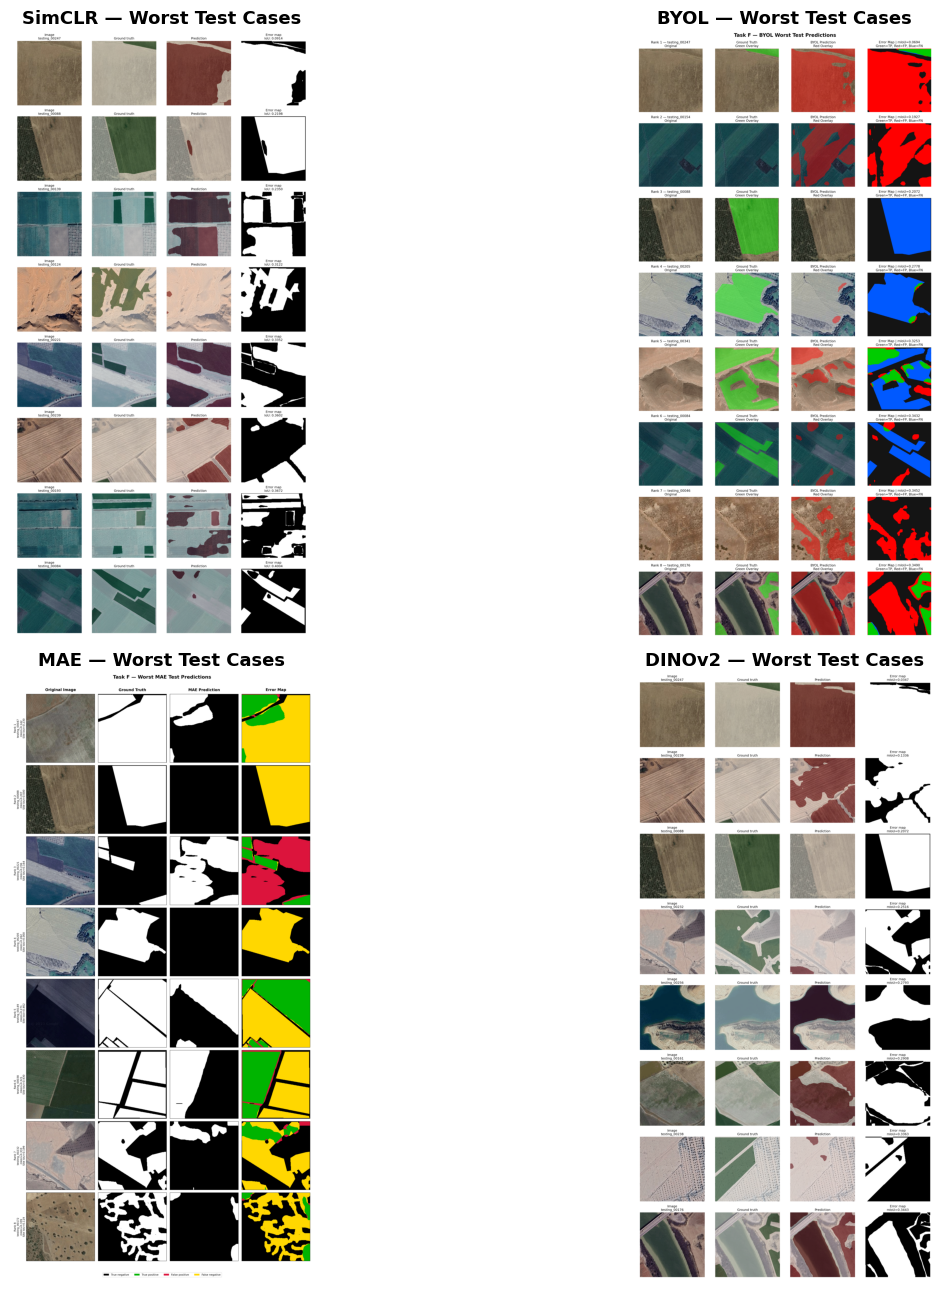

Saved four-method Task-F visual grid: /kaggle/working/PartB_Final_Comparison_outputs/figures/final_four_ssl_worst_case_grids_2x2.png
Part-A worst-case PNG was not attached. The objective Part-A comparison above still uses the attached per-image table when available, otherwise the verified Part-A worst-5 fallback.


In [12]:
error_plots = {
    method:
        ARTIFACTS[
            method
        ][
            "worst_plot"
        ]
    for method
    in METHODS
}


missing_ssl_error_plots = [
    method
    for method, path
    in error_plots.items()
    if (
        path is None
        or not Path(
            path
        ).exists()
    )
]


assert not missing_ssl_error_plots, (
    "Missing saved Task-F worst-case visualization for: "
    + ", ".join(
        missing_ssl_error_plots
    )
    + ". Attach all four executed SSL method outputs."
)


fig, axes = plt.subplots(
    2,
    2,
    figsize=(16, 13),
)


panel_order = [
    ("SimCLR", axes[0, 0]),
    ("BYOL", axes[0, 1]),
    ("MAE", axes[1, 0]),
    ("DINOv2", axes[1, 1]),
]


for method, axis in panel_order:
    image = Image.open(
        error_plots[
            method
        ]
    ).convert(
        "RGB"
    )

    axis.imshow(
        image
    )

    axis.set_title(
        f"{method} — Worst Test Cases",
        fontsize=13,
        fontweight="bold",
    )

    axis.axis(
        "off"
    )


plt.tight_layout()


SAVED_ERROR_GRID = (
    FIGURE_ROOT
    / "final_four_ssl_worst_case_grids_2x2.png"
)


plt.savefig(
    SAVED_ERROR_GRID,
    dpi=140,
    bbox_inches="tight",
)

plt.show()


print(
    "Saved four-method Task-F visual grid:",
    SAVED_ERROR_GRID
)


if (
    PARTA_WORST_PLOT
    and Path(
        PARTA_WORST_PLOT
    ).exists()
):
    plt.figure(
        figsize=(14, 8)
    )

    plt.imshow(
        Image.open(
            PARTA_WORST_PLOT
        ).convert(
            "RGB"
        )
    )

    plt.title(
        "Part-A Best Model — Saved Worst Cases"
    )

    plt.axis(
        "off"
    )

    plt.tight_layout()

    PARTA_ERROR_FIGURE_PATH = (
        FIGURE_ROOT
        / "parta_saved_worst_case_figure.png"
    )

    plt.savefig(
        PARTA_ERROR_FIGURE_PATH,
        dpi=140,
        bbox_inches="tight",
    )

    plt.show()

else:
    print(
        "Part-A worst-case PNG was not attached. "
        "The objective Part-A comparison above still uses the attached "
        "per-image table when available, otherwise the verified Part-A "
        "worst-5 fallback."
    )

## Error Analysis Discussion 

### Task F — Error Analysis Discussion

From the error analysis, we found that some difficult test images were common across different models, while others were specific to a particular SSL method. SimCLR shared two of its worst cases with Part A (`testing_00124` and `testing_00247`), while BYOL and DINOv2 each shared `testing_00247`; MAE did not share any of its worst five images with Part A. One image that stood out was `testing_00088`, because it appeared among the worst cases of all four SSL methods but not in the Part-A worst set. We also noticed that the **Landing-site class was harder to segment than the Background class for every model**. The Landing-site IoU was lower for Part A as well as SimCLR, BYOL, MAE, and DINOv2. Overall, this suggests that there are some common hard examples across the models, but each SSL method also has its own failure pattern. 

## 5. Save Final Comparison Package

In [13]:
final_payload = {
    "dataset": CONFIG["dataset"],
    "part_a_source": str(parta_source),
    "split_counts": {
        "part_a_train_labels": PARTA_TRAIN_LABELS,
        "part_b_finetune_labels": PARTB_FINETUNE_LABELS,
        "test_images": TEST_IMAGES,
    },
    "label_fraction_vs_part_a": float(LABEL_RATIO),
    "label_reduction_fraction": float(LABEL_REDUCTION),
    "test_split_double_role_acknowledged": True,
    "comparison_table": (
        comparison_df.replace({np.nan: None}).to_dict(orient="records")
    ),
    "ssl_ranking_by_miou": (
        ssl_ranking_df.replace({np.nan: None}).to_dict(orient="records")
    ),
    "worst_image_overlap_counts": (
        overlap_df.to_dict() if len(overlap_df) else {}
    ),
    "task_f_ssl_vs_parta_overlap": (
        task_f_parta_overlap_df.to_dict(
            orient="records"
        )
    ),
    "task_f_class_iou_comparison": (
        task_f_class_comparison_df.to_dict(
            orient="records"
        )
    ),
    "part_a_metric_source": str(
        parta_source
    ),
    "part_a_source_is_fallback": bool(
        PARTA_SOURCE_IS_FALLBACK
    ),
    "saved_at": datetime.now(timezone.utc).isoformat(),
}

FINAL_JSON = OUTPUT_ROOT / "final_part_b_comparison.json"
FINAL_JSON.write_text(
    json.dumps(final_payload, indent=2),
    encoding="utf-8",
)

summary_lines = [
    "PART B - FINAL SSL COMPARISON SUMMARY",
    "",
    "Dataset:",
    CONFIG["dataset"],
    "",
    f"Part-A fully supervised labels: {PARTA_TRAIN_LABELS}",
    f"Each SSL fine-tuning labels: {PARTB_FINETUNE_LABELS}",
    f"SSL label fraction: {100 * LABEL_RATIO:.2f}%",
    f"Label reduction: {100 * LABEL_REDUCTION:.2f}%",
    "",
    f"Part-A mIoU: {PARTA_MIOU:.6f}",
    "",
    "SSL ranking by final test mIoU:",
]

for rank, (_, row) in enumerate(ssl_ranking_df.iterrows(), start=1):
    summary_lines.append(
        f"{rank}. {row['Model']}: {row['mIoU']:.6f}"
    )


summary_lines.extend([
    "",
    "Part-A metric source:",
    str(
        parta_source
    ),
    "",
    (
        "Part-A source status: verified embedded fallback"
        if PARTA_SOURCE_IS_FALLBACK
        else "Part-A source status: attached executed output"
    ),
])


SUMMARY = OUTPUT_ROOT / "FINAL_PART_B_COMPARISON_SUMMARY.txt"
SUMMARY.write_text(
    "\n".join(summary_lines),
    encoding="utf-8",
)

for path in OUTPUT_ROOT.glob("*.csv"):
    shutil.copy2(path, PACKAGE_ROOT / path.name)

for path in OUTPUT_ROOT.glob("*.json"):
    shutil.copy2(path, PACKAGE_ROOT / path.name)

for path in OUTPUT_ROOT.glob("*.txt"):
    shutil.copy2(path, PACKAGE_ROOT / path.name)

for path in FIGURE_ROOT.glob("*.png"):
    shutil.copy2(path, PACKAGE_ROOT / path.name)

ZIP_PATH = Path(
    shutil.make_archive(
        str(OUTPUT_ROOT / "part_b_final_comparison_package"),
        "zip",
        PACKAGE_ROOT,
    )
)

print("Saved final JSON:", FINAL_JSON)
print("Saved summary:", SUMMARY)
print("Saved ZIP:", ZIP_PATH)

Saved final JSON: /kaggle/working/PartB_Final_Comparison_outputs/final_part_b_comparison.json
Saved summary: /kaggle/working/PartB_Final_Comparison_outputs/FINAL_PART_B_COMPARISON_SUMMARY.txt
Saved ZIP: /kaggle/working/PartB_Final_Comparison_outputs/part_b_final_comparison_package.zip


## 6. Final Output Check

In [14]:
required = [
    OUTPUT_ROOT
    / "final_ssl_label_efficiency_comparison.csv",

    OUTPUT_ROOT
    / "final_ssl_method_ranking.csv",

    OUTPUT_ROOT
    / "task_e_objective_numbers.csv",

    OUTPUT_ROOT
    / "task_e_label_efficiency_discussion.txt",

    FIGURE_ROOT
    / "final_ssl_miou_comparison.png",

    FIGURE_ROOT
    / "final_ssl_label_efficiency_chart.png",

    FIGURE_ROOT
    / "final_ssl_classwise_iou_comparison.png",

    FIGURE_ROOT
    / "all_four_ssl_confusion_matrices_2x2.png",

    OUTPUT_ROOT
    / "final_consolidated_worst_images.csv",

    OUTPUT_ROOT
    / "final_worst_image_overlap_counts.csv",

    OUTPUT_ROOT
    / "final_worst_image_overlap_jaccard.csv",

    OUTPUT_ROOT
    / "task_f_class_iou_comparison.csv",

    OUTPUT_ROOT
    / "task_f_ssl_vs_parta_worst_overlap.csv",

    OUTPUT_ROOT
    / "task_f_common_ssl_failure_images.csv",

    FIGURE_ROOT
    / "final_worst_image_overlap_heatmap.png",

    FIGURE_ROOT
    / "final_four_ssl_worst_case_grids_2x2.png",

    OUTPUT_ROOT
    / "final_part_b_comparison.json",

    OUTPUT_ROOT
    / "FINAL_PART_B_COMPARISON_SUMMARY.txt",

    OUTPUT_ROOT
    / "part_b_final_comparison_package.zip",
]


check_df = pd.DataFrame([
    {
        "artifact":
            path.name,

        "exists":
            path.exists(),

        "path":
            str(
                path
            ),
    }

    for path
    in required
])


display(
    check_df
)


assert check_df[
    "exists"
].all(), (
    "One or more final-comparison artifacts are missing."
)


print(
    "Final comparison outputs are ready."
)


if PARTA_SOURCE_IS_FALLBACK:
    print(
        "\\nSubmission note: the notebook is using the verified embedded "
        "Part-A result. If the executed Part-A best-model output/results.json "
        "is available, attach it and rerun for the strictest match to the "
        "Final Comparison instruction."
    )
else:
    print(
        "\\nPart-A metrics were loaded from an attached executed output."
    )


print(
    "\\nRun this notebook end-to-end with all cell outputs visible "
    "before submission."
)

,artifact,exists,path
0,final_ssl_label_efficiency_comparison.csv,True,/kaggle/working/PartB_Final_Comparison_outputs...
1,final_ssl_method_ranking.csv,True,/kaggle/working/PartB_Final_Comparison_outputs...
2,task_e_objective_numbers.csv,True,/kaggle/working/PartB_Final_Comparison_outputs...
3,task_e_label_efficiency_discussion.txt,True,/kaggle/working/PartB_Final_Comparison_outputs...
4,final_ssl_miou_comparison.png,True,/kaggle/working/PartB_Final_Comparison_outputs...
5,final_ssl_label_efficiency_chart.png,True,/kaggle/working/PartB_Final_Comparison_outputs...
6,final_ssl_classwise_iou_comparison.png,True,/kaggle/working/PartB_Final_Comparison_outputs...
7,all_four_ssl_confusion_matrices_2x2.png,True,/kaggle/working/PartB_Final_Comparison_outputs...
8,final_consolidated_worst_images.csv,True,/kaggle/working/PartB_Final_Comparison_outputs...
9,final_worst_image_overlap_counts.csv,True,/kaggle/working/PartB_Final_Comparison_outputs...


Final comparison outputs are ready.
\nSubmission note: the notebook is using the verified embedded Part-A result. If the executed Part-A best-model output/results.json is available, attach it and rerun for the strictest match to the Final Comparison instruction.
\nRun this notebook end-to-end with all cell outputs visible before submission.
